In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")

In [3]:
df = pd.read_csv("../data/ai4i2020.csv")   # use "data/ai4i2020.csv" if this path failed before
df.head()

,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0


In [4]:
df = df.rename(columns={
    "Air temperature [K]": "air_temp",
    "Process temperature [K]": "process_temp",
    "Rotational speed [rpm]": "rpm",
    "Torque [Nm]": "torque",
    "Tool wear [min]": "tool_wear",
    "Machine failure": "failure"
})
df.columns

Index(['UDI', 'Product ID', 'Type', 'air_temp', 'process_temp', 'rpm',
       'torque', 'tool_wear', 'failure', 'TWF', 'HDF', 'PWF', 'OSF', 'RNF'],
      dtype='str')

In [5]:
df["failure"].value_counts()

failure
0    9661
1     339
Name: count, dtype: int64

In [6]:
df["failure"].value_counts(normalize=True) * 100

failure
0    96.61
1     3.39
Name: proportion, dtype: float64

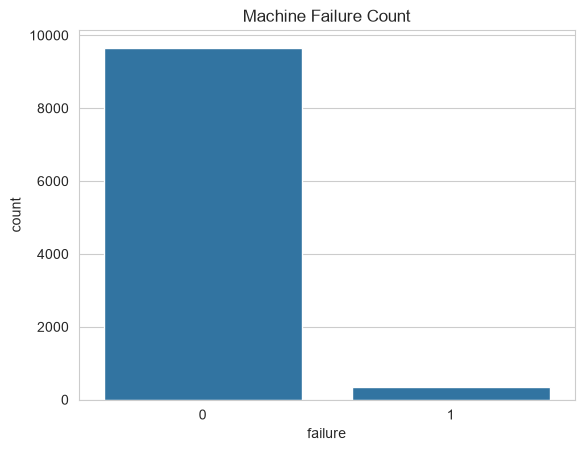

In [7]:
sns.countplot(x="failure", data=df)
plt.title("Machine Failure Count")
plt.show()

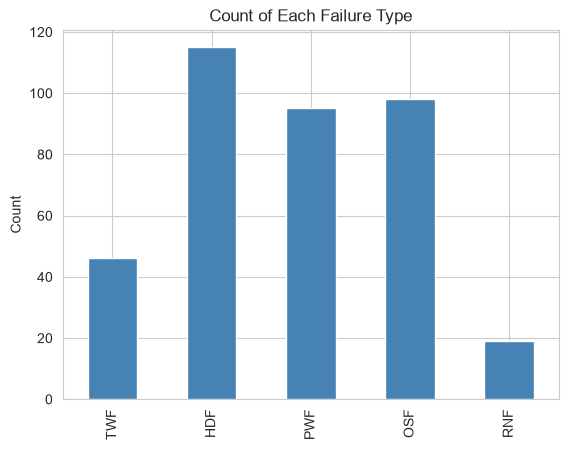

In [9]:
failure_types = ["TWF", "HDF", "PWF", "OSF", "RNF"]
df[failure_types].sum()
df[failure_types].sum().plot(kind="bar", color="steelblue")
plt.title("Count of Each Failure Type")
plt.ylabel("Count")
plt.show()

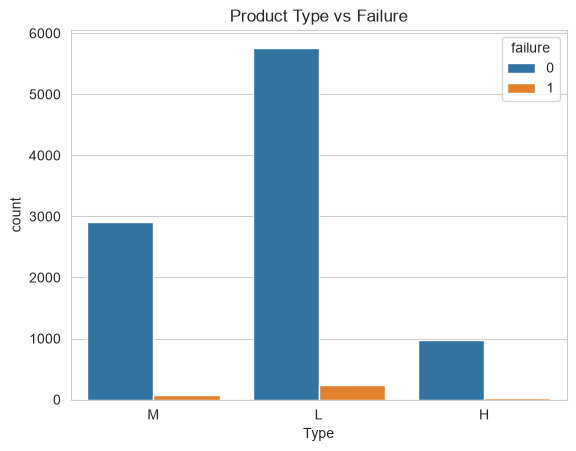

In [10]:
sns.countplot(x="Type", hue="failure", data=df)
plt.title("Product Type vs Failure")
plt.show()


In [11]:
df.groupby("Type")["failure"].mean() * 100

Type
H    2.093719
L    3.916667
M    2.769436
Name: failure, dtype: float64

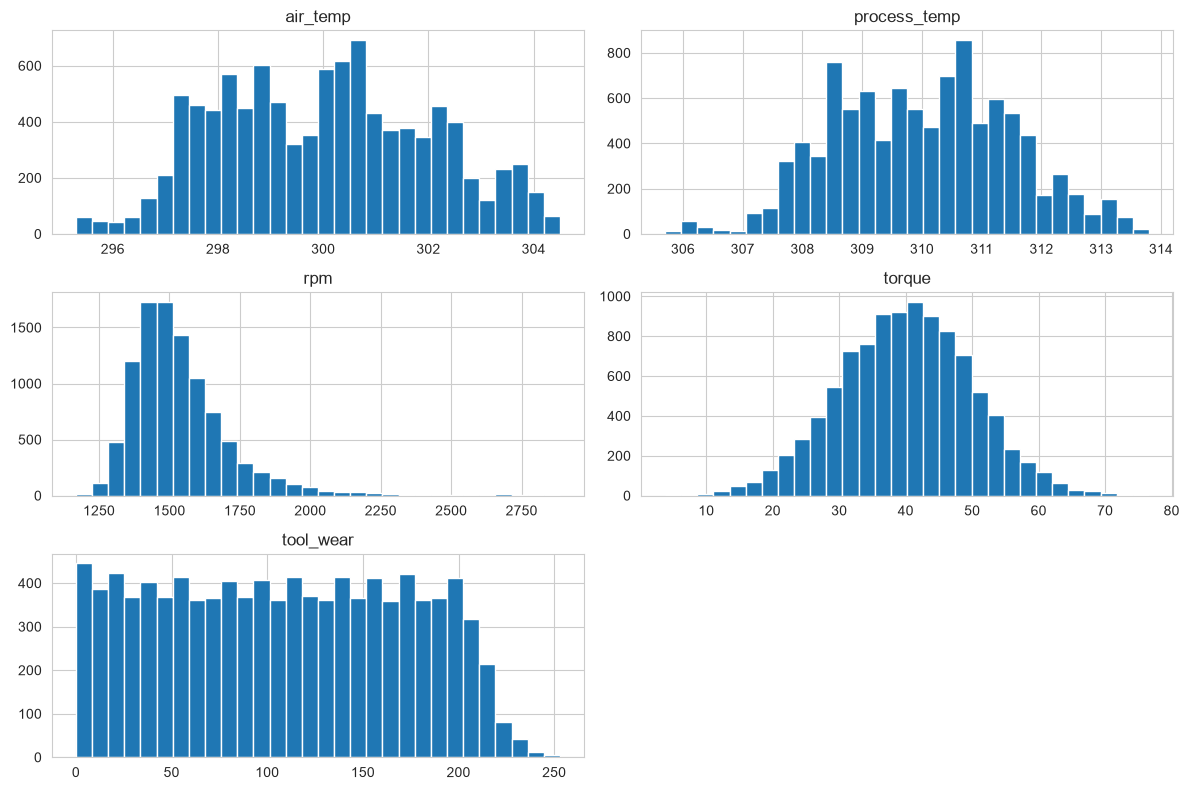

In [12]:
features = ["air_temp", "process_temp", "rpm", "torque", "tool_wear"]

df[features].hist(bins=30, figsize=(12, 8))
plt.tight_layout()
plt.show()

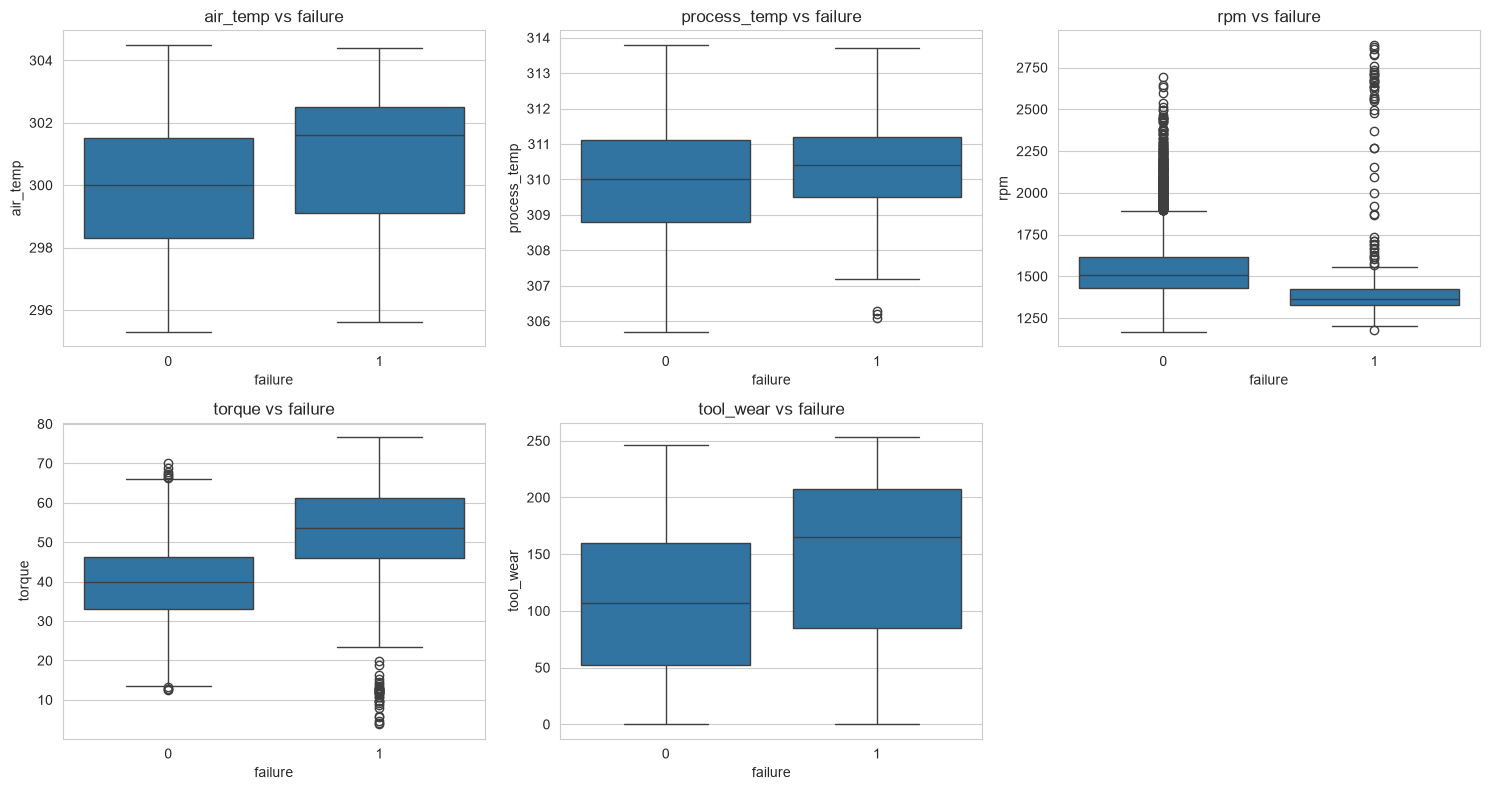

In [13]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
axes = axes.ravel()

for i, col in enumerate(features):
    sns.boxplot(x="failure", y=col, data=df, ax=axes[i])
    axes[i].set_title(f"{col} vs failure")

axes[5].axis("off")
plt.tight_layout()
plt.show()

In [14]:
df.groupby("failure")[features].mean()

,air_temp,process_temp,rpm,torque,tool_wear
failure,,,,,
0,299.973999,309.995570,1540.260014,39.629655,106.693717
1,300.886431,310.290265,1496.486726,50.168142,143.781711


In [15]:
df.groupby("failure")[features].mean()

,air_temp,process_temp,rpm,torque,tool_wear
failure,,,,,
0,299.973999,309.995570,1540.260014,39.629655,106.693717
1,300.886431,310.290265,1496.486726,50.168142,143.781711


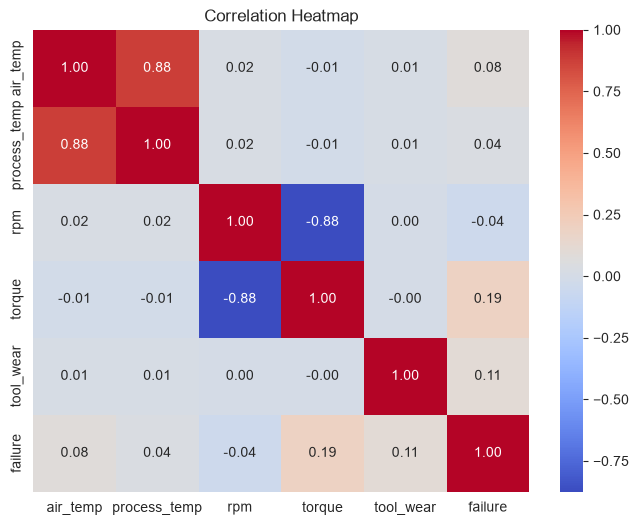

In [16]:
plt.figure(figsize=(8, 6))
sns.heatmap(df[features + ["failure"]].corr(), annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Heatmap")
plt.show()

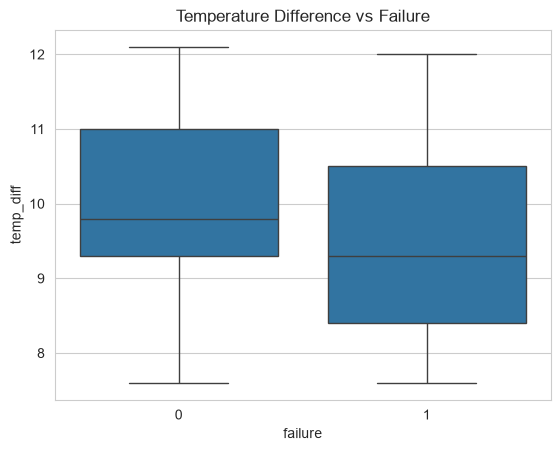

In [17]:
df["temp_diff"] = df["process_temp"] - df["air_temp"]

sns.boxplot(x="failure", y="temp_diff", data=df)
plt.title("Temperature Difference vs Failure")
plt.show()